In [29]:
from typing import TypedDict
import random
from langgraph.graph import StateGraph,START,END

In [30]:
class AgentState(TypedDict):
    name : str
    counting : int
    value : list

In [31]:
def greetingNode(state : AgentState) -> AgentState:
    state['name'] = f"Hi there, {state["name"]}"
    state['counting'] = 0
    return state
def random_node(state : AgentState) -> AgentState:
    state['value'].append(random.randint(0,10))
    state['counting'] += 1
    return state
def should_continue(state : AgentState) -> AgentState:
    if state['counting'] < 5:
        return "loop"
    else :
        return "exit"

In [32]:
graph = StateGraph(AgentState)
graph.add_node("greeting_Node",greetingNode)
graph.add_node("random_node",random_node)
graph.add_edge("greeting_Node","random_node")
graph.add_conditional_edges(
    "random_node",
    should_continue,
    {
        "loop" : "random_node",
        "exit" : END
    }
)
graph.set_entry_point("greeting_Node")
app = graph.compile()

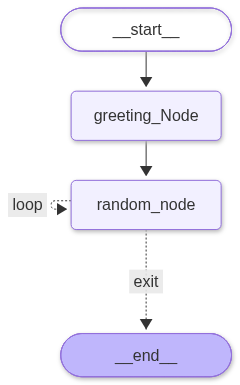

In [33]:
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))

In [34]:
result = AgentState(
    name="manoj",
    value=[],
    counting= -1,

)

In [35]:
print(app.invoke(result))

{'name': 'Hi there, manoj', 'counting': 5, 'value': [7, 10, 8, 4, 10]}
